In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Dataset/loan.csv")

In [3]:
df.shape

(200, 3)

In [4]:
df.head()

,x1,x2,y
0,3.729417,6.694052,rejected
1,6.282660,1.952843,approved
2,5.524101,2.296845,approved
3,-0.248258,5.732238,rejected
4,1.738760,4.701953,rejected


<AxesSubplot:xlabel='x1', ylabel='x2'>

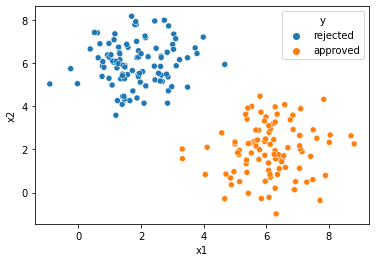

In [5]:
sns.scatterplot(x='x1',y='x2',hue='y',data=df)

In [6]:
def transform(x):
    if(x=="rejected"):
        return 1
    else:
        return -1
    
df['y'] = df['y'].apply(transform)

In [7]:
X = df.drop("y", axis=1).values
Y = df["y"].values

In [13]:
# Initializing a randon W and W0

W = np.random.normal(size=(2,))
W0 = np.random.normal()

<AxesSubplot:xlabel='x1', ylabel='x2'>

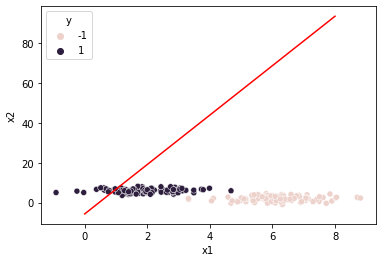

In [14]:
# plotting the random line

x_val = np.array([0,8])
y_val = (-W[0]*x_val - W0)/W[1]

plt.plot(x_val, y_val, 'r')
sns.scatterplot(x='x1', y='x2', data=df, hue='y')

In [15]:
def show(W, W0):
    x_val = np.array([0,8])
    y_val = (-W[0]*x_val - W0)/W[1]
    
    plt.plot(x_val, y_val, 'r')
    sns.scatterplot(x='x1', y='x2', data=df, hue='y')
    plt.show()

In [16]:
def distance_from_hyperplane(W, W0, X):
    return (np.dot(W,X)+W0)/np.linalg.norm(W)

In [17]:
def perceptron_training(W, W0, X, Y,num_itr=100):
    
    for itr in range(num_itr):
        print("Iteration number : ",itr)
        misclassification = 0
        for i in range(X.shape[0]):
            di = distance_from_hyperplane(W, W0, X[i])
            di_sign = np.sign(di)
            
            if di_sign != Y[i]:
                W = W + (Y[i]*X[i])
                W0 = W0 + Y[i]
                misclassification += 1
                
        print("Total Misclassification : ",misclassification)
        if(misclassification == 0):
            return W, W0

In [18]:
W_best, W0_best = perceptron_training(W, W0, X, Y)

Iteration number :  0
Total Misclassification :  4
Iteration number :  1
Total Misclassification :  0


In [19]:
W_best, W0_best

(array([-6.31478191,  7.79507174]), -0.825889509456116)

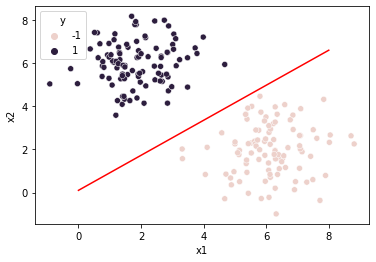

In [20]:
show(W_best, W0_best)

In [21]:
def gain_function(W, W0, X):
    
    total_distance = 0
    for i in range(X.shape[0]):
        di = distance_from_hyperplane(W, W0, X[i])
        total_distance += np.abs(di)
        
    average_distance = total_distance/X.shape[0]
    return average_distance
    

In [22]:
gain_function(W_best, W0_best, X)

2.8954678581030904

In [23]:
#random line

gain_function(W, W0, X)

3.274113692217715